# Chapter 17 · FX and multi-asset options: interactive demos

Companion to Chapter 17 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/17-multi-asset.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

The course's currency inputs: GBP/USD $=1.20$, EUR/USD $=1.02$, one-year rates $r_{\mathrm{USD}}=3\%$,
$r_{\mathrm{GBP}}=2.5\%$, $r_{\mathrm{EUR}}=1\%$, and volatilities $11\%$ (GBP/USD) and $10\%$ (EUR/USD).

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider

from mfe230d import bs
from mfe230d import multiasset as M
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN = "#1BAF7A"
FX = M.FX

## 1. One option, two currencies

A call on one pound struck at $K$ dollars is worth, in dollars, $X_0K$ times a pound-denominated put on one dollar
struck at $1/K$ pounds (Proposition 17.3(v)). The dollar investor prices under the domestic measure $\mathbb Q$,
where $X$ drifts at $r_d-r_f$; the pound investor under the foreign measure $\mathbb Q_f$, where $1/X$ drifts at
$r_f-r_d$. The left panel shows the two closed forms against the strike; the right panel estimates the call (ATMF
by default) by simulation under each measure, from the same normal draws.

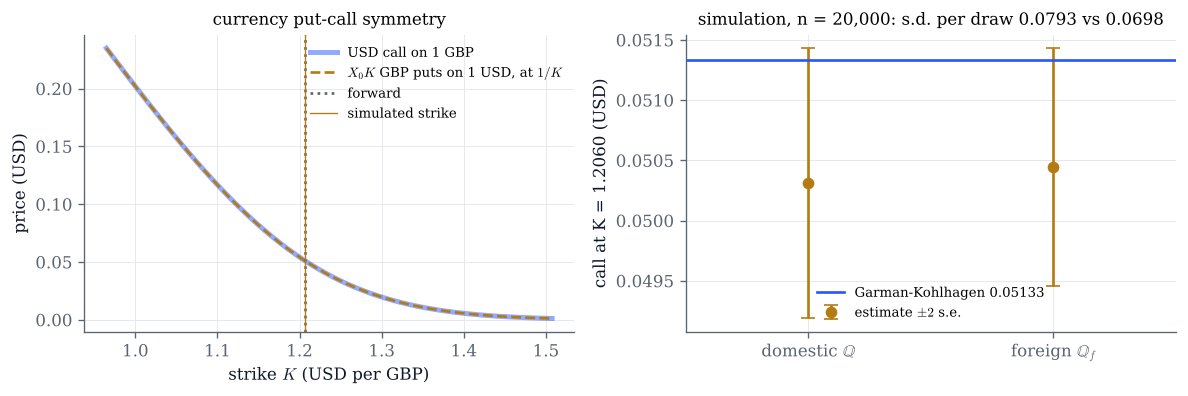

In [2]:
def two_currencies(sigma=0.11, r_d=0.03, r_f=0.025, T=1.0, moneyness=1.0, n=20_000, seed=1):
    X = FX["X_gbp"]
    F = M.fx_forward(X, T, r_d, r_f)
    Ks = np.linspace(0.8 * F, 1.25 * F, 60)
    call = M.garman_kohlhagen(X, Ks, T, r_d, r_f, sigma)
    dual = X * Ks * M.garman_kohlhagen(1 / X, 1 / Ks, T, r_f, r_d, sigma, "put")
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(Ks, call, color=COBALT, lw=3, alpha=0.5, label="USD call on 1 GBP")
    ax.plot(Ks, dual, color=GOLD, ls="--", label="$X_0K$ GBP puts on 1 USD, at $1/K$")
    ax.axvline(F, color=GREY, ls=":", label="forward")
    ax.axvline(moneyness * F, color=GOLD, lw=0.8, label="simulated strike")
    ax.set(xlabel="strike $K$ (USD per GBP)", ylabel="price (USD)", title="currency put-call symmetry")
    ax.legend(fontsize=8)
    z = np.random.default_rng(seed).standard_normal(n)
    Xd = X * np.exp((r_d - r_f - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * z)        # under Q
    Xf = X * np.exp((r_d - r_f + 0.5 * sigma**2) * T + sigma * np.sqrt(T) * z)        # under Q_f
    Ksim = moneyness * F
    est_d = np.exp(-r_d * T) * np.maximum(Xd - Ksim, 0)
    est_f = X * np.exp(-r_f * T) * np.maximum(1 - Ksim / Xf, 0)
    exact = float(M.garman_kohlhagen(X, Ksim, T, r_d, r_f, sigma))
    names = ["domestic $\\mathbb{Q}$", "foreign $\\mathbb{Q}_f$"]
    means = [est_d.mean(), est_f.mean()]
    ses = [2 * est_d.std() / np.sqrt(n), 2 * est_f.std() / np.sqrt(n)]
    bx.errorbar([0, 1], means, yerr=ses, fmt="o", color=GOLD, capsize=4, label="estimate $\\pm2$ s.e.")
    bx.axhline(exact, color=COBALT, label=f"Garman-Kohlhagen {exact:.5f}")
    bx.set(xticks=[0, 1], xticklabels=names, xlim=(-0.5, 1.5), ylabel=f"call at K = {Ksim:.4f} (USD)",
           title=f"simulation, n = {n:,}: s.d. per draw {est_d.std():.4f} vs {est_f.std():.4f}")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

two_currencies()

In [3]:
# Explore: the identity holds for every input. Which measure gives the smaller variance, and when?
interact(two_currencies,
         sigma=FloatSlider(value=0.11, min=0.02, max=0.5, step=0.01, continuous_update=False, description="σ"),
         r_d=FloatSlider(value=0.03, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r_d"),
         r_f=FloatSlider(value=0.025, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r_f"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         moneyness=FloatSlider(value=1.0, min=0.7, max=1.4, step=0.02, continuous_update=False, description="K / F"),
         n=IntSlider(value=20_000, min=2_000, max=200_000, step=2_000, continuous_update=False, description="n"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 2. Exchange options and the volatility triangle

For a dollar investor, a GBP/EUR option is an option to exchange euros for pounds, priced by Margrabe's formula
(Theorem 17.6) with the cross volatility $\sigma_{12}=\sqrt{\sigma_1^2-2\rho\sigma_1\sigma_2+\sigma_2^2}$. Correlations in
$[-1,1]$ allow only $\sigma_{12}\in[|\sigma_1-\sigma_2|,\sigma_1+\sigma_2]$. The right panel shows the USD value of the ATMF
GBP/EUR call against the correlation, with simulated values from correlated draws (principal-components factor,
so that $\rho=\pm1$ works too).

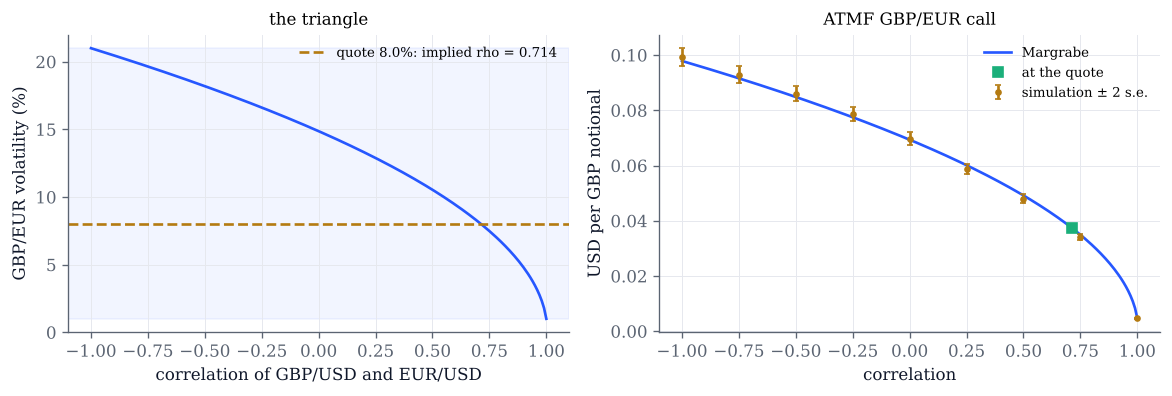

In [4]:
def triangle(sigma1=0.11, sigma2=0.10, quote=0.08, n=2**13, seed=17):
    fx = dict(FX, vol_gbp=sigma1, vol_eur=sigma2)
    rhos = np.linspace(-1, 1, 201)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(rhos, 100 * M.exchange_vol(sigma1, sigma2, rhos), color=COBALT)
    lo, hi = M.cross_vol_range(sigma1, sigma2)
    ax.axhspan(100 * lo, 100 * hi, color=COBALT, alpha=0.06)
    rq = M.implied_correlation(sigma1, sigma2, quote)
    ok = -1 <= rq <= 1
    ax.axhline(100 * quote, color=GOLD, ls="--", label=f"quote {100 * quote:.1f}%: implied rho = {rq:.3f}"
               + ("" if ok else "  (impossible)"))
    ax.set(xlabel="correlation of GBP/USD and EUR/USD", ylabel="GBP/EUR volatility (%)", title="the triangle")
    ax.legend(fontsize=8)
    bx.plot(rhos, [M.cross_atmf_call(rho=r, fx=fx)[0] for r in rhos], color=COBALT, label="Margrabe")
    F12 = M.cross_atmf_call(rho=0, fx=fx)[1]
    Z = np.random.default_rng(seed).standard_normal((n, 2))
    grid = np.linspace(-1, 1, 9)
    est, err = [], []
    for r in grid:
        ST = M.terminal_prices([fx["X_gbp"], fx["X_eur"]], 1.0, fx["r_usd"], [fx["r_gbp"], fx["r_eur"]],
                               [sigma1, sigma2], [[1, r], [r, 1]], Z=Z, method="pca")
        pay = np.exp(-fx["r_usd"]) * np.maximum(ST[:, 0] - F12 * ST[:, 1], 0)
        est.append(pay.mean()); err.append(2 * pay.std() / np.sqrt(n))
    bx.errorbar(grid, est, yerr=err, fmt="o", color=GOLD, capsize=2, ms=3, label="simulation ± 2 s.e.")
    if ok:
        bx.plot([rq], [M.cross_atmf_call(s12=quote, fx=fx)[0]], "s", color=GREEN, label="at the quote")
    bx.set(xlabel="correlation", ylabel="USD per GBP notional", title="ATMF GBP/EUR call")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

triangle()

In [5]:
# Explore: make the two volatilities equal and look at rho = 1. Put the quote outside the triangle.
interact(triangle,
         sigma1=FloatSlider(value=0.11, min=0.02, max=0.4, step=0.01, continuous_update=False, description="σ1"),
         sigma2=FloatSlider(value=0.10, min=0.02, max=0.4, step=0.01, continuous_update=False, description="σ2"),
         quote=FloatSlider(value=0.08, min=0.0, max=0.6, step=0.005, continuous_update=False, description="σ12 quote"),
         n=IntSlider(value=2**13, min=2**10, max=2**16, step=2**10, continuous_update=False, description="n"),
         seed=IntSlider(value=17, min=0, max=50, continuous_update=False, description="seed"));

## 3. Quantos: the correlation enters the drift

A quanto call pays $\bar X(S_T-K)^+$ in dollars for a pound-denominated index $S$. Under the dollar measure the index
drifts at $r_f-y-\rho\sigma_S\sigma_X$ (Proposition 17.8), so its price depends on the correlation $\rho$ between the index
and GBP/USD. The plot compares the quanto with the ordinary call converted at the spot rate and the composite call
struck in dollars, against $\rho$, with a simulated check at the chosen $\rho$.

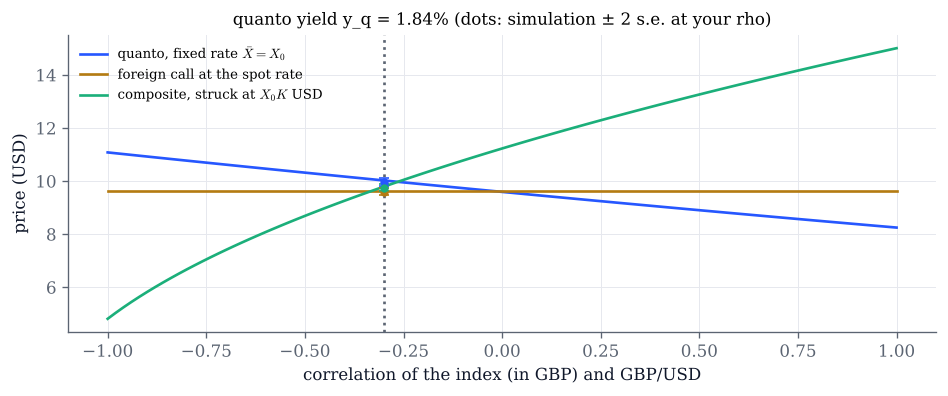

In [6]:
def quanto(rho=-0.3, sigma_S=0.20, sigma_X=0.11, r_d=0.03, r_f=0.025, n=50_000, seed=3):
    S, K, T, y, X0 = 100.0, 100.0, 1.0, 0.02, FX["X_gbp"]
    rhos = np.linspace(-1, 1, 101)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(rhos, M.quanto_option(S, K, T, r_d, r_f, y, sigma_S, sigma_X, rhos, Xbar=X0), color=COBALT,
            label="quanto, fixed rate $\\bar X=X_0$")
    ax.plot(rhos, np.full_like(rhos, float(M.foreign_option(S, X0, K, T, r_f, y, sigma_S))), color=GOLD,
            label="foreign call at the spot rate")
    ax.plot(rhos, [float(M.composite_option(S, X0, X0 * K, T, r_d, y, sigma_S, sigma_X, r)) for r in rhos],
            color=GREEN, label="composite, struck at $X_0K$ USD")
    Sf, Xt = M.fx_equity_terminal(S, X0, T, r_d, r_f, y, sigma_S, sigma_X, rho, n=n, seed=seed)
    D = np.exp(-r_d * T)
    for pay, col in ((D * X0 * np.maximum(Sf - K, 0), COBALT), (D * Xt * np.maximum(Sf - K, 0), GOLD),
                     (D * np.maximum(Xt * Sf - X0 * K, 0), GREEN)):
        ax.errorbar([rho], [pay.mean()], yerr=[2 * pay.std() / np.sqrt(n)], fmt="o", color=col, capsize=3, ms=4)
    ax.axvline(rho, color=GREY, ls=":")
    yq = M.quanto_yield(y, r_d, r_f, sigma_S, sigma_X, rho)
    ax.set(xlabel="correlation of the index (in GBP) and GBP/USD", ylabel="price (USD)",
           title=f"quanto yield y_q = {100 * yq:.2f}% (dots: simulation ± 2 s.e. at your rho)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

quanto()

In [7]:
# Explore: when does the quanto cost more than the foreign call? What does sigma_X do when rho = 0?
interact(quanto,
         rho=FloatSlider(value=-0.3, min=-1, max=1, step=0.05, continuous_update=False, description="ρ"),
         sigma_S=FloatSlider(value=0.20, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ_S"),
         sigma_X=FloatSlider(value=0.11, min=0.02, max=0.4, step=0.01, continuous_update=False, description="σ_X"),
         r_d=FloatSlider(value=0.03, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r_d"),
         r_f=FloatSlider(value=0.025, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r_f"),
         n=IntSlider(value=50_000, min=5_000, max=500_000, step=5_000, continuous_update=False, description="n"),
         seed=IntSlider(value=3, min=0, max=50, continuous_update=False, description="seed"));

## 4. Baskets: the geometric control and the approximations

A three-asset basket call $(\frac13\sum_iS_{i,T}-K)^+$, here with a common correlation $\rho$ between all pairs. The left
panel shows the standard deviation per draw of plain Monte Carlo, of the geometric control (Proposition 17.10) and
of the three controls of Example 17.12; the right panel the errors of the two-moment and Gentle approximations and of the conditioning
lower bound, against a reference computed by integrating out the geometric direction exactly (Remark 17.11).

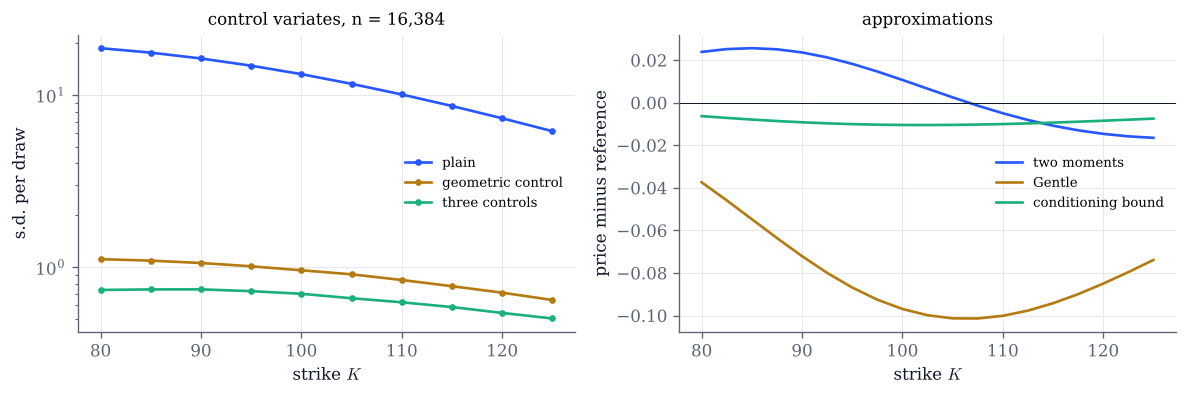

In [8]:
def basket(sigma1=0.20, sigma2=0.25, sigma3=0.30, rho=0.5, T=1.0, n=2**14, seed=17):
    S, w, y, r = np.full(3, 100.0), np.full(3, 1 / 3), np.full(3, 0.02), 0.01
    sig = np.array([sigma1, sigma2, sigma3])
    corr = np.full((3, 3), rho); np.fill_diagonal(corr, 1.0)
    Z = np.random.default_rng(seed).standard_normal((n, 3))
    Ks = np.linspace(80, 125, 10)
    sd = {"plain": [], "geometric control": [], "three controls": []}
    for K in Ks:
        a = (S, w, K, T, r, y, sig, corr)
        sd["plain"].append(M.basket_mc(*a, Z=Z)["se"] * np.sqrt(n))
        sd["geometric control"].append(M.basket_mc(*a, Z=Z, controls=("geometric",))["se"] * np.sqrt(n))
        sd["three controls"].append(M.basket_mc(*a, Z=Z, controls=("geometric", "forward", "strip"))["se"] * np.sqrt(n))
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    for (k, v), c in zip(sd.items(), (COBALT, GOLD, GREEN)):
        ax.semilogy(Ks, v, color=c, marker="o", ms=3, label=k)
    ax.set(xlabel="strike $K$", ylabel="s.d. per draw", title=f"control variates, n = {n:,}")
    ax.legend(fontsize=8)
    Kf = np.linspace(80, 125, 19)
    errs = {"two moments": [], "Gentle": [], "conditioning bound": []}
    for K in Kf:
        a = (S, w, K, T, r, y, sig, corr)
        ref = M.basket_reference(*a, nodes=24)
        errs["two moments"].append(M.basket_lognormal(*a) - ref)
        errs["Gentle"].append(M.gentle_call(*a) - ref)
        try:
            errs["conditioning bound"].append(M.curran_lower_bound(*a) - ref)
        except ValueError:                      # some c_i < 0: the bound is not available
            errs["conditioning bound"].append(np.nan)
    for (k, v), c in zip(errs.items(), (COBALT, GOLD, GREEN)):
        bx.plot(Kf, v, color=c, label=k)
    bx.axhline(0, color=INK, lw=0.6)
    bx.set(xlabel="strike $K$", ylabel="price minus reference", title="approximations")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

basket()

In [9]:
# Explore: lower the correlation (down to -0.45, the edge of positive definiteness for three assets) and watch
# the control and the approximations degrade together.
interact(basket,
         sigma1=FloatSlider(value=0.20, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ1"),
         sigma2=FloatSlider(value=0.25, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ2"),
         sigma3=FloatSlider(value=0.30, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ3"),
         rho=FloatSlider(value=0.5, min=-0.45, max=0.95, step=0.05, continuous_update=False, description="ρ"),
         T=FloatSlider(value=1.0, min=0.25, max=5.0, step=0.25, continuous_update=False, description="T"),
         n=IntSlider(value=2**14, min=2**11, max=2**17, step=2**11, continuous_update=False, description="n"),
         seed=IntSlider(value=17, min=0, max=50, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $r_d=r_f$. Is the ATMF call then worth the same in both currencies, in units of the notional?
  Which of the two simulations has the smaller variance for deep in-the-money strikes, and why?
- In section 2, set $\sigma_1=\sigma_2$ and move $\rho$ to $1$: what is the cross option worth, and why is that obvious?
- In section 3, set $\rho=0$ and move $\sigma_X$. Then set $r_d=r_f$ and move $\rho$. Which inputs does the quanto
  really depend on?
- In section 4, raise all three volatilities together, then spread them apart at a fixed average. Which hurts the
  geometric control more: high volatility or dispersed volatilities?